<a href="https://colab.research.google.com/github/Aaronfs04/Animal_Classification/blob/main/GSLC_DeepLearning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [13]:
import torchvision.datasets as datasets

dataset_trainval = datasets.OxfordIIITPet(
    root="./data",
    split="trainval",
    target_types="category",
    download=True
)

dataset_test = datasets.OxfordIIITPet(
    root="./data",
    split="test",
    target_types="category",    download=True
)


In [14]:
import torch
import torch.nn as nn
import torchvision.datasets as datasets
from torchvision import models, transforms
from torch.utils.data import DataLoader, Subset, Dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
import numpy as np
import random
import time
import os

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

aug_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(224, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

base_transforms = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class TransformSubset(Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform
    def __getitem__(self, index):
        x, y = self.subset[index]
        if self.transform: x = self.transform(x)
        return x, y
    def __len__(self): return len(self.subset)

dataset_trainval = datasets.OxfordIIITPet(root="./data", split="trainval", target_types="category", download=True)
dataset_test = datasets.OxfordIIITPet(root="./data", split="test", target_types="category", download=True)

full_data = [(img, lbl) for ds in [dataset_trainval, dataset_test] for img, lbl in ds if lbl < 10]
full_targets = [lbl for _, lbl in full_data]

train_idx, temp_idx, _, temp_labels = train_test_split(list(range(len(full_data))), full_targets, test_size=0.30, stratify=full_targets, random_state=42)
val_idx, test_idx, _, _ = train_test_split(temp_idx, temp_labels, test_size=0.50, stratify=temp_labels, random_state=42)

train_subset = Subset(full_data, train_idx)
val_subset = Subset(full_data, val_idx)
test_subset = Subset(full_data, test_idx)

def run_experiment(model, optimizer, train_transform, mode_name, max_epochs=30, patience=4):
    print(f"\n{'='*40}\nMEMULAI EKSPERIMEN: {mode_name}\n{'='*40}")

    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    print(f"Trainable Parameters: {trainable_params:,}")

    train_loader = DataLoader(TransformSubset(train_subset, train_transform), batch_size=32, shuffle=True)
    val_loader = DataLoader(TransformSubset(val_subset, base_transforms), batch_size=32, shuffle=False)
    test_loader = DataLoader(TransformSubset(test_subset, base_transforms), batch_size=32, shuffle=False)

    criterion = nn.CrossEntropyLoss()
    best_val_loss = float('inf')
    epochs_no_improve = 0
    start_time = time.time()

    train_losses = []
    val_losses = []

    for epoch in range(max_epochs):
        model.train()
        train_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            loss = criterion(model(inputs), labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * inputs.size(0)

        model.eval()
        val_loss, val_preds, val_targets = 0.0, [], []
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                val_loss += criterion(outputs, labels).item() * inputs.size(0)
                val_preds.extend(torch.max(outputs, 1)[1].cpu().numpy())
                val_targets.extend(labels.cpu().numpy())

        epoch_train_loss = train_loss / len(train_loader.dataset)
        epoch_val_loss = val_loss / len(val_loader.dataset)
        train_losses.append(epoch_train_loss)
        val_losses.append(epoch_val_loss)

        val_acc = accuracy_score(val_targets, val_preds)
        print(f"Epoch {epoch+1:02d} | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {val_acc:.4f}")

        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1
            if epochs_no_improve >= patience:
                print(f"--> Early stopping dipicu pada epoch {epoch+1}!")
                break

    print(f"Durasi Pelatihan Total: {(time.time() - start_time)/60:.2f} menit")

    model.eval()
    test_preds, test_targets = [], []
    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            test_preds.extend(preds.cpu().numpy())
            test_targets.extend(labels.cpu().numpy())

    test_acc = accuracy_score(test_targets, test_preds)
    test_f1 = f1_score(test_targets, test_preds, average='macro')

    print(f"*** HASIL TEST SET: Akurasi = {test_acc:.4f} | Macro F1-Score = {test_f1:.4f} ***")

    return model, train_losses, val_losses, test_f1

In [15]:
#B1
set_seed(42)
model_b1 = models.resnet18(weights=None)
model_b1.fc = nn.Linear(model_b1.fc.in_features, 10)
model_b1 = model_b1.to(device)

optimizer_b1 = torch.optim.AdamW(model_b1.parameters(), lr=1e-3)

model_b1, tr_loss_b1, val_loss_b1, f1_b1 = run_experiment(
    model=model_b1,
    optimizer=optimizer_b1,
    train_transform=aug_transforms,
    mode_name="B1 - Baseline from Scratch"
)


MEMULAI EKSPERIMEN: B1 - Baseline from Scratch
Trainable Parameters: 11,181,642
Epoch 01 | Train Loss: 2.3201 | Val Loss: 2.2307 | Val Acc: 0.1987
Epoch 02 | Train Loss: 2.0154 | Val Loss: 2.2473 | Val Acc: 0.3064
Epoch 03 | Train Loss: 1.9172 | Val Loss: 1.9570 | Val Acc: 0.3098
Epoch 04 | Train Loss: 1.7946 | Val Loss: 2.1826 | Val Acc: 0.3165
Epoch 05 | Train Loss: 1.7623 | Val Loss: 2.1309 | Val Acc: 0.3131
Epoch 06 | Train Loss: 1.6544 | Val Loss: 1.7735 | Val Acc: 0.4040
Epoch 07 | Train Loss: 1.6423 | Val Loss: 1.7230 | Val Acc: 0.4108
Epoch 08 | Train Loss: 1.5870 | Val Loss: 1.7462 | Val Acc: 0.4074
Epoch 09 | Train Loss: 1.4812 | Val Loss: 1.7088 | Val Acc: 0.3973
Epoch 10 | Train Loss: 1.4783 | Val Loss: 1.5666 | Val Acc: 0.4848
Epoch 11 | Train Loss: 1.3948 | Val Loss: 1.7239 | Val Acc: 0.4310
Epoch 12 | Train Loss: 1.3926 | Val Loss: 1.5598 | Val Acc: 0.4646
Epoch 13 | Train Loss: 1.3534 | Val Loss: 1.5980 | Val Acc: 0.4545
Epoch 14 | Train Loss: 1.2692 | Val Loss: 1.6909

In [16]:
#B2
set_seed(42)
model_b2 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model_b2.parameters():
    param.requires_grad = False

model_b2.fc = nn.Linear(model_b2.fc.in_features, 10)
model_b2 = model_b2.to(device)

optimizer_b2 = torch.optim.AdamW(model_b2.fc.parameters(), lr=1e-3)

model_b2, tr_loss_b2, val_loss_b2, f1_b2 = run_experiment(
    model=model_b2,
    optimizer=optimizer_b2,
    train_transform=aug_transforms,
    mode_name="B2 - Feature Extraction"
)


MEMULAI EKSPERIMEN: B2 - Feature Extraction
Trainable Parameters: 5,130
Epoch 01 | Train Loss: 1.6565 | Val Loss: 0.9035 | Val Acc: 0.8215
Epoch 02 | Train Loss: 0.7789 | Val Loss: 0.5390 | Val Acc: 0.8721
Epoch 03 | Train Loss: 0.5521 | Val Loss: 0.4269 | Val Acc: 0.8923
Epoch 04 | Train Loss: 0.4464 | Val Loss: 0.3542 | Val Acc: 0.8990
Epoch 05 | Train Loss: 0.3859 | Val Loss: 0.3281 | Val Acc: 0.9024
Epoch 06 | Train Loss: 0.3689 | Val Loss: 0.3222 | Val Acc: 0.9057
Epoch 07 | Train Loss: 0.3400 | Val Loss: 0.3088 | Val Acc: 0.9024
Epoch 08 | Train Loss: 0.3174 | Val Loss: 0.2802 | Val Acc: 0.9024
Epoch 09 | Train Loss: 0.2811 | Val Loss: 0.2765 | Val Acc: 0.9091
Epoch 10 | Train Loss: 0.2654 | Val Loss: 0.2628 | Val Acc: 0.9125
Epoch 11 | Train Loss: 0.2649 | Val Loss: 0.2671 | Val Acc: 0.9057
Epoch 12 | Train Loss: 0.2644 | Val Loss: 0.2683 | Val Acc: 0.9024
Epoch 13 | Train Loss: 0.2426 | Val Loss: 0.2505 | Val Acc: 0.9192
Epoch 14 | Train Loss: 0.2440 | Val Loss: 0.2456 | Val A

In [17]:
#B3
set_seed(42)
model_b3 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model_b3.parameters():
    param.requires_grad = False

for param in model_b3.layer4.parameters():
    param.requires_grad = True

model_b3.fc = nn.Linear(model_b3.fc.in_features, 10)
model_b3 = model_b3.to(device)

optimizer_b3 = torch.optim.AdamW([
    {"params": model_b3.layer4.parameters(), "lr": 1e-4},
    {"params": model_b3.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

model_b3, tr_loss_b3, val_loss_b3, f1_b3 = run_experiment(
    model=model_b3,
    optimizer=optimizer_b3,
    train_transform=aug_transforms,
    mode_name="B3 - Progressive Fine-Tuning"
)


MEMULAI EKSPERIMEN: B3 - Progressive Fine-Tuning
Trainable Parameters: 8,398,858
Epoch 01 | Train Loss: 0.9141 | Val Loss: 0.3179 | Val Acc: 0.8923
Epoch 02 | Train Loss: 0.2575 | Val Loss: 0.2328 | Val Acc: 0.9158
Epoch 03 | Train Loss: 0.1546 | Val Loss: 0.2191 | Val Acc: 0.9327
Epoch 04 | Train Loss: 0.1029 | Val Loss: 0.2398 | Val Acc: 0.9192
Epoch 05 | Train Loss: 0.0594 | Val Loss: 0.2553 | Val Acc: 0.9158
Epoch 06 | Train Loss: 0.0558 | Val Loss: 0.2652 | Val Acc: 0.9259
Epoch 07 | Train Loss: 0.0415 | Val Loss: 0.2693 | Val Acc: 0.9024
--> Early stopping dipicu pada epoch 7!
Durasi Pelatihan Total: 1.51 menit
*** HASIL TEST SET: Akurasi = 0.9195 | Macro F1-Score = 0.9198 ***


In [18]:
#B4
set_seed(42)
model_b4 = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)

for param in model_b4.parameters():
    param.requires_grad = False

for param in model_b4.layer4.parameters():
    param.requires_grad = True

model_b4.fc = nn.Linear(model_b4.fc.in_features, 10)
model_b4 = model_b4.to(device)

optimizer_b4 = torch.optim.AdamW([
    {"params": model_b4.layer4.parameters(), "lr": 1e-4},
    {"params": model_b4.fc.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

model_b4, tr_loss_b4, val_loss_b4, f1_b4 = run_experiment(
    model=model_b4,
    optimizer=optimizer_b4,
    train_transform=base_transforms,
    mode_name="B4 - Uji Kontrol (Tanpa Augmentasi)"
)


MEMULAI EKSPERIMEN: B4 - Uji Kontrol (Tanpa Augmentasi)
Trainable Parameters: 8,398,858
Epoch 01 | Train Loss: 0.8361 | Val Loss: 0.2792 | Val Acc: 0.9057
Epoch 02 | Train Loss: 0.1500 | Val Loss: 0.2080 | Val Acc: 0.9327
Epoch 03 | Train Loss: 0.0457 | Val Loss: 0.2090 | Val Acc: 0.9394
Epoch 04 | Train Loss: 0.0220 | Val Loss: 0.2002 | Val Acc: 0.9360
Epoch 05 | Train Loss: 0.0152 | Val Loss: 0.2059 | Val Acc: 0.9293
Epoch 06 | Train Loss: 0.0092 | Val Loss: 0.2071 | Val Acc: 0.9293
Epoch 07 | Train Loss: 0.0049 | Val Loss: 0.1915 | Val Acc: 0.9428
Epoch 08 | Train Loss: 0.0045 | Val Loss: 0.1910 | Val Acc: 0.9360
Epoch 09 | Train Loss: 0.0032 | Val Loss: 0.1905 | Val Acc: 0.9394
Epoch 10 | Train Loss: 0.0032 | Val Loss: 0.2126 | Val Acc: 0.9394
Epoch 11 | Train Loss: 0.0026 | Val Loss: 0.1950 | Val Acc: 0.9360
Epoch 12 | Train Loss: 0.0017 | Val Loss: 0.1999 | Val Acc: 0.9360
Epoch 13 | Train Loss: 0.0016 | Val Loss: 0.1933 | Val Acc: 0.9360
--> Early stopping dipicu pada epoch 13!

In [19]:
#B5
set_seed(42)
model_b5 = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)

for param in model_b5.parameters():
    param.requires_grad = False

for param in model_b5.features[-1].parameters():
    param.requires_grad = True

model_b5.classifier[1] = nn.Linear(model_b5.classifier[1].in_features, 10)
model_b5 = model_b5.to(device)

optimizer_b5 = torch.optim.AdamW([
    {"params": model_b5.features[-1].parameters(), "lr": 1e-4},
    {"params": model_b5.classifier.parameters(), "lr": 1e-3},
], weight_decay=1e-2)

model_b5, tr_loss_b5, val_loss_b5, f1_b5 = run_experiment(
    model=model_b5,
    optimizer=optimizer_b5,
    train_transform=aug_transforms,
    mode_name="B5 - EfficientNet-B0 Pembanding"
)


MEMULAI EKSPERIMEN: B5 - EfficientNet-B0 Pembanding
Trainable Parameters: 424,970
Epoch 01 | Train Loss: 1.4822 | Val Loss: 0.8051 | Val Acc: 0.8721
Epoch 02 | Train Loss: 0.6845 | Val Loss: 0.5038 | Val Acc: 0.8855
Epoch 03 | Train Loss: 0.5146 | Val Loss: 0.3851 | Val Acc: 0.9125
Epoch 04 | Train Loss: 0.4130 | Val Loss: 0.3531 | Val Acc: 0.9057
Epoch 05 | Train Loss: 0.3554 | Val Loss: 0.3239 | Val Acc: 0.9057
Epoch 06 | Train Loss: 0.3216 | Val Loss: 0.2878 | Val Acc: 0.9091
Epoch 07 | Train Loss: 0.2894 | Val Loss: 0.2787 | Val Acc: 0.9226
Epoch 08 | Train Loss: 0.2492 | Val Loss: 0.2747 | Val Acc: 0.9024
Epoch 09 | Train Loss: 0.2280 | Val Loss: 0.2795 | Val Acc: 0.9125
Epoch 10 | Train Loss: 0.2008 | Val Loss: 0.2516 | Val Acc: 0.9192
Epoch 11 | Train Loss: 0.1896 | Val Loss: 0.2590 | Val Acc: 0.9057
Epoch 12 | Train Loss: 0.1866 | Val Loss: 0.2594 | Val Acc: 0.9125
Epoch 13 | Train Loss: 0.1589 | Val Loss: 0.2519 | Val Acc: 0.9125
Epoch 14 | Train Loss: 0.1417 | Val Loss: 0.26

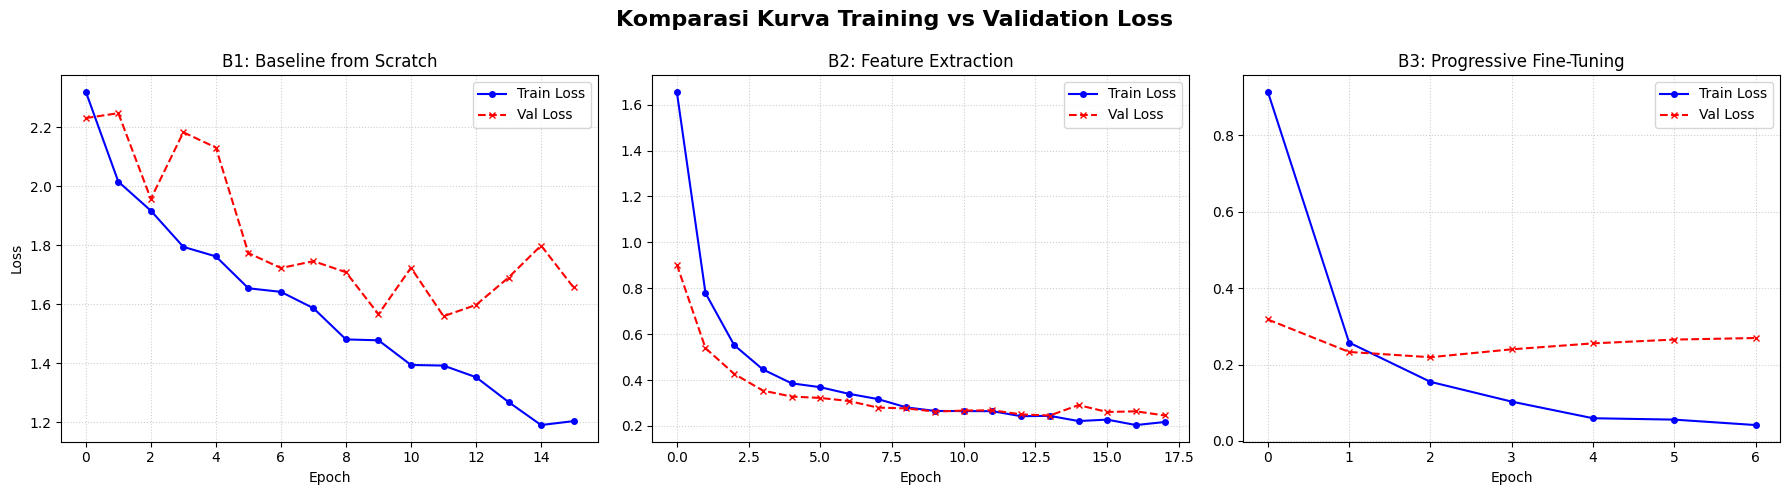

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('Komparasi Kurva Training vs Validation Loss', fontsize=16, fontweight='bold')

axes[0].plot(tr_loss_b1, label='Train Loss', color='blue', marker='o', markersize=4)
axes[0].plot(val_loss_b1, label='Val Loss', color='red', linestyle='--', marker='x', markersize=4)
axes[0].set_title('B1: Baseline from Scratch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(tr_loss_b2, label='Train Loss', color='blue', marker='o', markersize=4)
axes[1].plot(val_loss_b2, label='Val Loss', color='red', linestyle='--', marker='x', markersize=4)
axes[1].set_title('B2: Feature Extraction')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].plot(tr_loss_b3, label='Train Loss', color='blue', marker='o', markersize=4)
axes[2].plot(val_loss_b3, label='Val Loss', color='red', linestyle='--', marker='x', markersize=4)
axes[2].set_title('B3: Progressive Fine-Tuning')
axes[2].set_xlabel('Epoch')
axes[2].legend()
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()

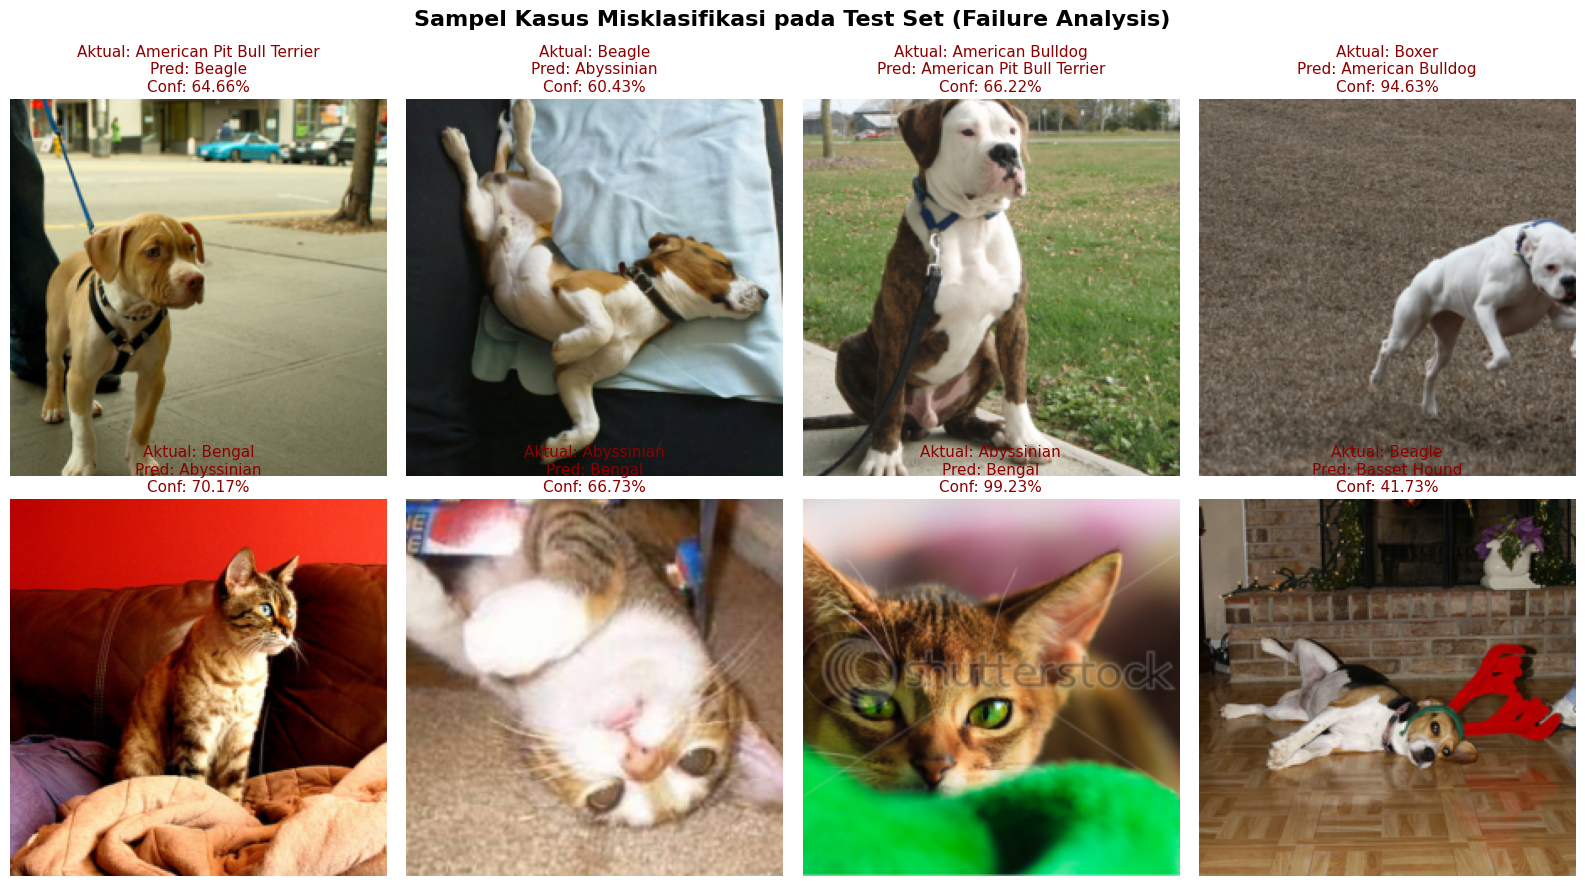

In [22]:
import matplotlib.pyplot as plt
import torch.nn.functional as F
import numpy as np
from torch.utils.data import DataLoader

test_loader = DataLoader(TransformSubset(test_subset, base_transforms), batch_size=32, shuffle=False)

best_model = model_b4
best_model.eval()

class_names = dataset_test.classes[:10]

misclassified_images = []
misclassified_trues = []
misclassified_preds = []
misclassified_probs = []

with torch.no_grad():
    for inputs, labels in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)
        outputs = best_model(inputs)

        probs = F.softmax(outputs, dim=1)
        max_probs, preds = torch.max(probs, 1)

        for i in range(len(preds)):
            if preds[i] != labels[i]:
                img = inputs[i].cpu().numpy().transpose((1, 2, 0))

                mean = np.array([0.485, 0.456, 0.406])
                std = np.array([0.229, 0.224, 0.225])
                img = std * img + mean
                img = np.clip(img, 0, 1)

                misclassified_images.append(img)
                misclassified_trues.append(labels[i].item())
                misclassified_preds.append(preds[i].item())
                misclassified_probs.append(max_probs[i].item())

                if len(misclassified_images) >= 8:
                    break
        if len(misclassified_images) >= 8:
            break

fig, axes = plt.subplots(2, 4, figsize=(16, 9))
fig.suptitle('Sampel Kasus Misklasifikasi pada Test Set (Failure Analysis)', fontsize=16, fontweight='bold')

for idx, ax in enumerate(axes.flatten()):
    if idx < len(misclassified_images):
        ax.imshow(misclassified_images[idx])
        t_label = class_names[misclassified_trues[idx]]
        p_label = class_names[misclassified_preds[idx]]
        conf = misclassified_probs[idx]

        ax.set_title(f"Aktual: {t_label}\nPred: {p_label}\nConf: {conf:.2%}", color='darkred', fontsize=11)
        ax.axis('off')
    else:
        ax.axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.88)
plt.show()

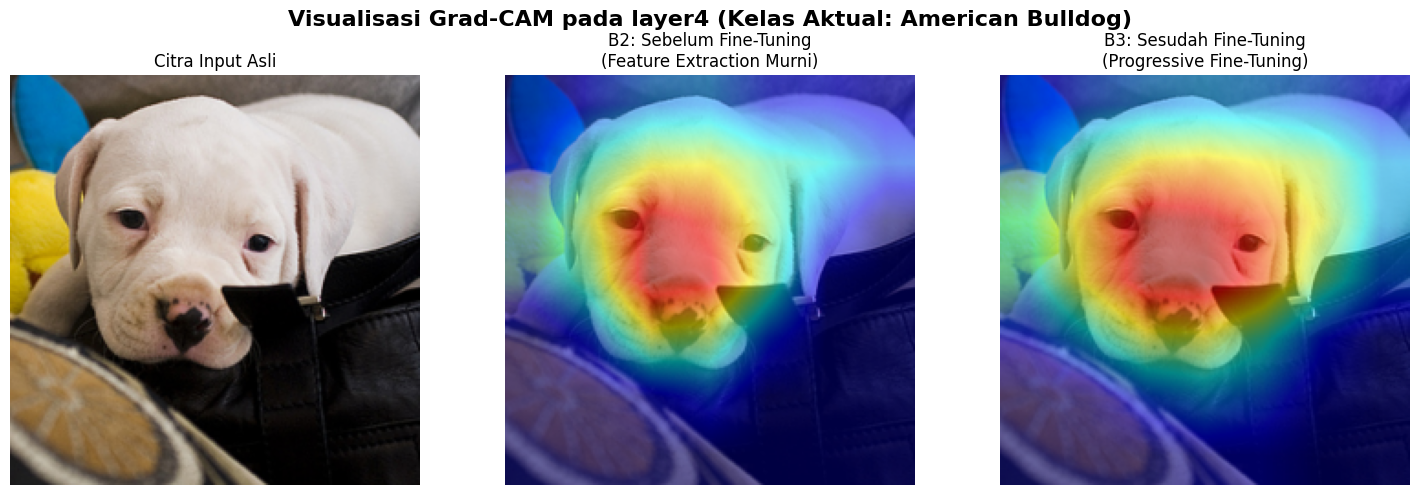

In [29]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

transformed_test_data = TransformSubset(test_subset, base_transforms)

sample_idx = 15
img_tensor, label = transformed_test_data[sample_idx]
img_tensor_unsqueeze = img_tensor.unsqueeze(0).to(device)

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])
img_rgb = img_tensor.cpu().numpy().transpose(1, 2, 0)
img_rgb = std * img_rgb + mean
img_rgb = np.clip(img_rgb, 0, 1)

for param in model_b2.layer4.parameters():
    param.requires_grad = True

model_b2.eval()
target_layers_b2 = [model_b2.layer4[-1]]
cam_b2 = GradCAM(model=model_b2, target_layers=target_layers_b2)

model_b4.eval()
target_layers_b4 = [model_b4.layer4[-1]]
cam_b4 = GradCAM(model=model_b4, target_layers=target_layers_b4)

targets = [ClassifierOutputTarget(label)]
grayscale_cam_b2 = cam_b2(input_tensor=img_tensor_unsqueeze, targets=targets)[0, :]
grayscale_cam_b4 = cam_b4(input_tensor=img_tensor_unsqueeze, targets=targets)[0, :]

cam_image_b2 = show_cam_on_image(img_rgb, grayscale_cam_b2, use_rgb=True)
cam_image_b4 = show_cam_on_image(img_rgb, grayscale_cam_b4, use_rgb=True)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle(f'Visualisasi Grad-CAM pada layer4 (Kelas Aktual: {dataset_test.classes[label]})', fontsize=16, fontweight='bold')

axes[0].imshow(img_rgb)
axes[0].set_title('Citra Input Asli')
axes[0].axis('off')

axes[1].imshow(cam_image_b2)
axes[1].set_title('B2: Sebelum Fine-Tuning\n(Feature Extraction Murni)')
axes[1].axis('off')

axes[2].imshow(cam_image_b4)
axes[2].set_title('B3: Sesudah Fine-Tuning\n(Progressive Fine-Tuning)')
axes[2].axis('off')

plt.tight_layout()
plt.subplots_adjust(top=0.85)
plt.show()

In [30]:
import json

# Menggabungkan seluruh data riwayat metrik ke dalam satu kamus (dictionary)
log_mentah = {
    "B1_Baseline_from_Scratch": {
        "train_loss": tr_loss_b1,
        "val_loss": val_loss_b1,
        "test_macro_f1": f1_b1
    },
    "B2_Feature_Extraction": {
        "train_loss": tr_loss_b2,
        "val_loss": val_loss_b2,
        "test_macro_f1": f1_b2
    },
    "B3_Progressive_Fine_Tuning": {
        "train_loss": tr_loss_b3,
        "val_loss": val_loss_b3,
        "test_macro_f1": f1_b3
    },
    "B4_Uji_Kontrol_Tanpa_Augmentasi": {
        "train_loss": tr_loss_b4,
        "val_loss": val_loss_b4,
        "test_macro_f1": f1_b4
    },
    "B5_EfficientNetB0": {
        "train_loss": tr_loss_b5,
        "val_loss": val_loss_b5,
        "test_macro_f1": f1_b5
    }
}

# Menyimpan data ke dalam file .json
with open('log_hasil_mentah.json', 'w') as file:
    json.dump(log_mentah, file, indent=4)

print("File log_hasil_mentah.json berhasil dibuat!")

File log_hasil_mentah.json berhasil dibuat!
